In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict, RandomizedSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
import xgboost as xgb
from catboost import CatBoostClassifier

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
data_train = pd.read_csv(Path('data/train.csv'))
data_test = pd.read_csv(Path('data/test.csv'))

### Data analysis

In [4]:
data_train.head(10)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0
5,5,10.74,0.12,4,18.05,51,53,1885.81,0,56.3,17,0,19.8,0,Groceries,Mastercard,PIN,ATM,Android Phone,False,False,True,False,False,False,0.0
6,6,20.56,4.99,3,18.07,54,78,769.62,0,15.3,17,5,19.7,0,Healthcare,Visa,3D Secure,Online,POS Terminal,False,False,False,False,False,False,0.0
7,7,38.08,12.08,6,11.53,52,24,4566.46,0,39.5,22,4,39.0,0,Restaurants,Mastercard,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
8,8,15.06,4.88,5,7.85,47,54,682.02,0,18.5,9,2,46.6,0,Restaurants,Visa,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
9,9,26.48,3.72,2,1.52,40,27,4973.30,0,9.3,6,3,41.0,0,Restaurants,Amex,Biometric,POS,Android Phone,False,True,False,False,False,False,0.0


In [5]:
data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [6]:
num_cols = ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
str_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
bool_cols = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

#### Analysis of each type of present datatype.

In [7]:
data_train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


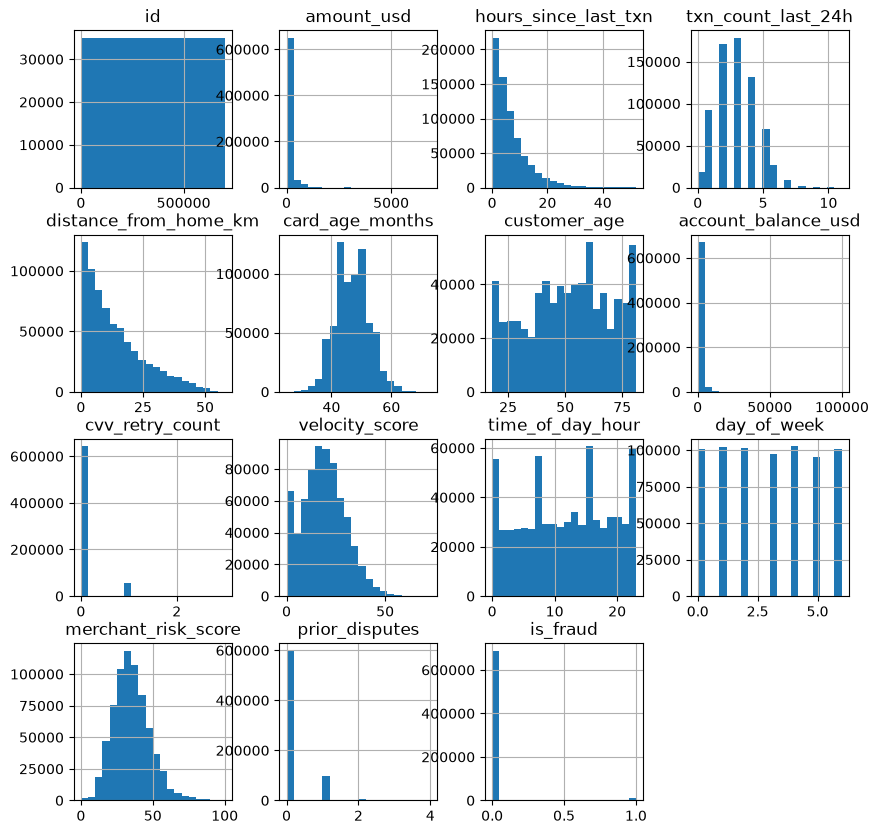

In [8]:
data_train.hist(bins=20, figsize=(10,10))
plt.show()

<Axes: >

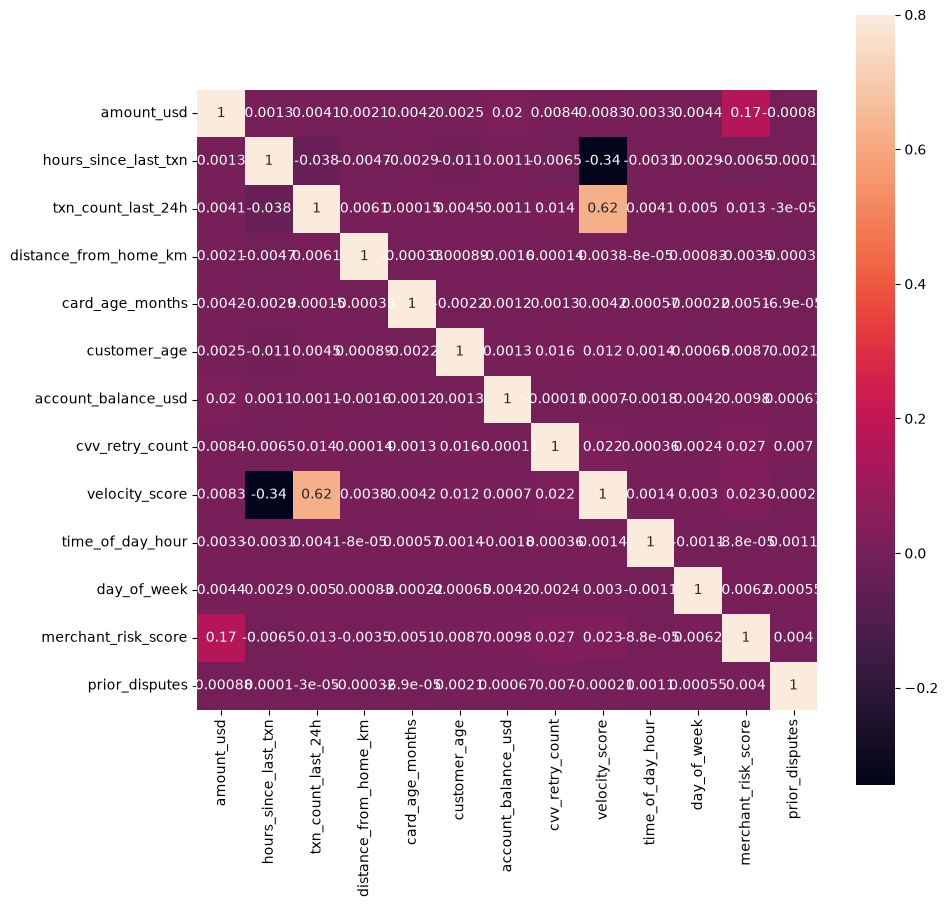

In [9]:
corrmat = data_train[num_cols].corr()
f, ax = plt.subplots(figsize=(10,10))
sns.heatmap(corrmat, vmax=.8, square=True, annot=True)

In [10]:
(data_train['is_fraud'] == 1).mean() * 100

np.float64(1.6699525687182124)

In [11]:
train_copy = data_train.drop(columns=['is_fraud']).copy()
y = data_train['is_fraud']

cat_cols = str_cols + bool_cols
encoder = OrdinalEncoder()
train_copy[cat_cols] = encoder.fit_transform(train_copy[cat_cols])

mi_scores = mutual_info_classif(train_copy, y)
mi_scores_series = pd.Series(mi_scores, index=train_copy.columns).sort_values(ascending=False)
mi_scores_series

card_type                       0.060114
channel                         0.048089
auth_method                     0.037305
txn_count_last_24h              0.034635
device_type                     0.030269
merchant_category               0.025181
day_of_week                     0.019774
is_new_merchant                 0.013614
cvv_retry_count                 0.013234
card_age_months                 0.008665
prior_disputes                  0.008647
merchant_risk_score             0.008528
time_of_day_hour                0.006430
velocity_score                  0.005801
customer_age                    0.005133
ip_country_mismatch             0.004120
is_foreign_transaction          0.002920
billing_shipping_mismatch       0.002305
used_vpn                        0.002263
hours_since_last_txn            0.001696
amount_usd                      0.001598
account_balance_usd             0.000962
is_ai_generated_scam_attempt    0.000684
distance_from_home_km           0.000386
id              

In [12]:
for str in str_cols:
    print(f"Current column: {str}")
    print(data_train[str].unique())
    print("\n")

Current column: merchant_category
<StringArray>
[      'Groceries',   'Online Retail',       'Utilities',     'Electronics',
      'Healthcare',     'Restaurants',            'Fuel',       'Streaming',
 'Crypto Exchange',          'Gaming',          'Travel',      'Gift Cards']
Length: 12, dtype: str


Current column: card_type
<StringArray>
['Mastercard', 'Visa', 'Amex', 'RuPay', 'Discover']
Length: 5, dtype: str


Current column: auth_method
<StringArray>
['OTP', 'PIN', '3D Secure', 'Biometric', 'No Authentication']
Length: 5, dtype: str


Current column: channel
<StringArray>
['POS', 'In-App', 'Online', 'ATM', 'Contactless']
Length: 5, dtype: str


Current column: device_type
<StringArray>
[       'iPhone', 'Android Phone',        'Tablet',    'Windows PC',
  'POS Terminal',           'Mac',   'ATM Machine',   'Smart Watch']
Length: 8, dtype: str




Dataset does not have any missing values inside of it, numerical features are mostly equally distributed with some columns right skewed. Additionally, the biggest correlations between features and fraud seem to be connected with categorical features like 'card_type' or 'channel', on another end of the spectrum seemingly important features like 'amount_usd' or 'account_balace_usd' have almost zero correlation with fraud but could definitely be used to tell to create some new features. Lastly Categorical features at most have 12 unique features but on average this numbers oscillates around 7.

### Feature engineering

In [13]:
train_copy['mean_amt_by_card'] = train_copy.groupby('card_type')['amount_usd'].transform('mean')

train_copy['amt_vs_card_mean_ratio'] = train_copy['amount_usd'] / train_copy['mean_amt_by_card']

train_copy['amt_vs_card_mean_diff'] = train_copy['amount_usd'] - train_copy['mean_amt_by_card']

del str
train_copy['card_channel'] = data_train['card_type'] + "_" + data_train['channel']
train_copy['card_channel'] = encoder.fit_transform(train_copy[['card_channel']].astype(str))

In [14]:
mi_scores = mutual_info_classif(train_copy, y)
mi_scores_series = pd.Series(mi_scores, index=train_copy.columns).sort_values(ascending=False)
mi_scores_series

mean_amt_by_card                0.063709
card_type                       0.060109
channel                         0.047693
auth_method                     0.037251
txn_count_last_24h              0.034765
device_type                     0.031036
merchant_category               0.025069
day_of_week                     0.019832
card_channel                    0.016697
is_new_merchant                 0.013747
cvv_retry_count                 0.013022
prior_disputes                  0.008848
merchant_risk_score             0.008694
card_age_months                 0.008530
time_of_day_hour                0.006689
velocity_score                  0.005981
customer_age                    0.005336
ip_country_mismatch             0.004230
is_foreign_transaction          0.002987
used_vpn                        0.002382
billing_shipping_mismatch       0.002193
hours_since_last_txn            0.001932
amount_usd                      0.001764
amt_vs_card_mean_ratio          0.001431
amt_vs_card_mean

The newly engineered features will not be included in the final model because they demonstrate lower predictive power than the baseline features. Keeping them would only add unnecessary dimensionality and noise, potentially degrading the model's generalization. Furthermore, the seemingly high score of the mean_amt_by_card feature was discarded because it acts as a direct numerical proxy for card_type rather than providing new insights, scoring slightly higher merely due to how algorithms process continuous variables.

### Creating a pipeline

Because of size of the dataset (699960 rows, 26 columns) model intended for this dataset will be LightGBM.

In [15]:
y_train = data_train['is_fraud'].copy()
data_train.drop("is_fraud", axis=1, inplace=True)

In [16]:
preprocessing = ColumnTransformer([
    ('drop_id', 'drop', ['id']),
    ('cat', OrdinalEncoder(), str_cols),
    ('num', 'passthrough', num_cols),
    ('bool', 'passthrough', bool_cols)
])

X_train = preprocessing.fit_transform(data_train)

In [17]:
lgbm_clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, n_jobs=-1, max_depth=6, subsample=0.8, colsample_bytree=0.8, class_weight='balanced', verbose=-1, random_state=42)
xgb_clf = xgb.XGBClassifier(scale_pos_weight=59, n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
cat_clf = CatBoostClassifier(iterations=500, auto_class_weights='Balanced', depth=6, subsample=0.8, colsample_bylevel=0.8, verbose=0, learning_rate=0.05, thread_count=-1,random_state=42)

In [18]:
for clf, name in zip([lgbm_clf, xgb_clf, cat_clf], ['LGBM', 'XGBoost', 'CatBoost']):
    probabilities = cross_val_predict(clf, X_train, y_train, cv=4, method='predict_proba')
    fraud_probs = probabilities[:, 1]
    roc = roc_auc_score(y_train, fraud_probs)

    print("~"*20+"\n")
    print(f"Trained model: {name}")
    print(f"Achieved ROC-AUC score: {round(roc,4)}\n")


~~~~~~~~~~~~~~~~~~~~

Trained model: LGBM
Achieved ROC-AUC score: 0.9434

~~~~~~~~~~~~~~~~~~~~

Trained model: XGBoost
Achieved ROC-AUC score: 0.9409

~~~~~~~~~~~~~~~~~~~~

Trained model: CatBoost
Achieved ROC-AUC score: 0.945

